# **SVM lineal para un clasificador binaria**

En este ejemplo usamos un SVM lineal para la clasificación binaria de un dataset que tiene como vectores (X,Y), cada ejemplo X es un vector de 4 columas ( Daily Time Spent on Site, Age,  Area Income,  Daily Internet Usage) y la etiqueta Y  que tiene la clase 1 si el ckiente hizo click y la Clase 0 si el cliente no hizo click. En este caso usamos las librerías de [sklearn](https://scikit-learn.org/stable/index.html) para probar el clasificador  de máquina de soporte vectorial SVM.


In [15]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt # data visualization
import seaborn as sns # statistical data visualization
%matplotlib inline

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, auc
from sklearn.svm import SVC

### **Los datos:**
Contamos con un conjunto de datos con información de varios posibles clientes que recibieron la publicidad, a continuación se presentan las columnas más relevantes para realizar el trabajo:
- **Daily Time Spent on Site:** tiempo que estuvo el cliente dentro de la página web (minutos)
- **Age:** edad del cliente (años)
- **Area Income:** Ingreso promedio de las personas ubicadas en la región geográfica del cliente
- **Daily Internet Usage:** Tiempo promedio de uso de internet del cliente al día (minutos)
- **Male:** Si el cliente es de sexo masculino
- **Clicked on Ad:** Si el cliente hizo click en la publicidad (1/0 para Sí/No)


In [16]:
data= pd.read_csv('data/advertising.csv')
data

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0
...,...,...,...,...,...,...,...,...,...,...
995,72.97,30,71384.57,208.58,Fundamental modular algorithm,Duffystad,1,Lebanon,2016-02-11 21:49:00,1
996,51.30,45,67782.17,134.42,Grass-roots cohesive monitoring,New Darlene,1,Bosnia and Herzegovina,2016-04-22 02:07:01,1
997,51.63,51,42415.72,120.37,Expanded intangible solution,South Jessica,1,Mongolia,2016-02-01 17:24:57,1
998,55.55,19,41920.79,187.95,Proactive bandwidth-monitored policy,West Steven,0,Guatemala,2016-03-24 02:35:54,0


In [17]:
data.head()

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,Clicked on Ad
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0


# **Separando la información del dataset**
Separar los datos en Input (X) y Output (y), para el Input seleccionar las columnas descritas inicialmente, no incluir ```Ad Topic Line```, ```City```, ```Country``` ni ```Timestamp```.
Separar los datos en Train y Test, dejar 80% de datos para entrenamiento

In [18]:
# Atributos relevantes
features = ['Daily Time Spent on Site', 'Age', 'Area Income', 'Daily Internet Usage', 'Male', 'Clicked on Ad']

# Separando en X y Y
X = data[features].drop('Clicked on Ad', axis=1)
y = data[features]['Clicked on Ad']


# Separando train y test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=101)

print(X_train,y_train)
print(len(X_train),len(y_train))

     Daily Time Spent on Site  Age  Area Income  Daily Internet Usage  Male
423                     58.03   31     28387.42                129.33     0
157                     41.73   28     61142.33                202.18     1
670                     77.89   26     64188.50                201.54     0
256                     80.91   32     61608.23                231.42     0
965                     35.25   50     47051.02                194.44     0
..                        ...  ...          ...                   ...   ...
575                     48.86   54     53188.69                134.46     0
838                     44.13   40     33601.84                128.48     1
337                     75.32   28     59998.50                233.60     1
523                     67.94   43     68447.17                128.16     0
863                     76.64   39     66217.31                241.50     1

[800 rows x 5 columns] 423    1
157    1
670    0
256    0
965    1
      ..
575    1
8

In [19]:
print(X_test,y_test)
print(len(X_test),len(y_test))

     Daily Time Spent on Site  Age  Area Income  Daily Internet Usage  Male
545                     42.60   55     55121.65                168.29     0
298                     80.39   31     66269.49                214.74     0
109                     74.02   32     72272.90                210.54     0
837                     55.77   49     55942.04                117.33     1
194                     77.20   33     49325.48                254.05     1
..                        ...  ...          ...                   ...   ...
68                      75.74   25     61005.87                215.25     1
449                     77.69   22     48852.58                169.88     1
715                     49.19   38     61004.51                123.08     0
793                     36.62   32     51119.93                162.44     1
688                     74.58   36     70701.31                230.52     0

[200 rows x 5 columns] 545    1
298    0
109    0
837    1
194    0
      ..
68     0
4

In [20]:
# Creacion del modelo lineal
linear_model = SVC(kernel='linear', probability=True)
linear_model.fit(X_train, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,True
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [21]:
# Predicciones
y_pred_2 = linear_model.predict(X_test)

In [22]:
def make_roc_curve(X_test, y_test, model):
    '''
    Funcion para construir y graficar una curva ROC e imprimir el AUC

    Parametros:
        X_test: cojunto de prueba para input
        y_test: cojunto de prueba para output
        model: el modelo
    '''
    probs = model.predict_proba(X_test)
    preds = probs[:,1]
    fpr, tpr, threshold = roc_curve(y_test, preds)
    roc_auc = auc(fpr, tpr)

    # Graficando la curva ROC con scikitplot
    skplt.metrics.plot_roc_curve(y_test, probs)
    plt.show()

    # AUC
    print("The AUC is {auc}".format(auc=roc_auc))

In [23]:
!pip install scikit-plot

zsh:1: command not found: pip


Matriz de Confusión:
 [[103   2]
 [  4  91]]


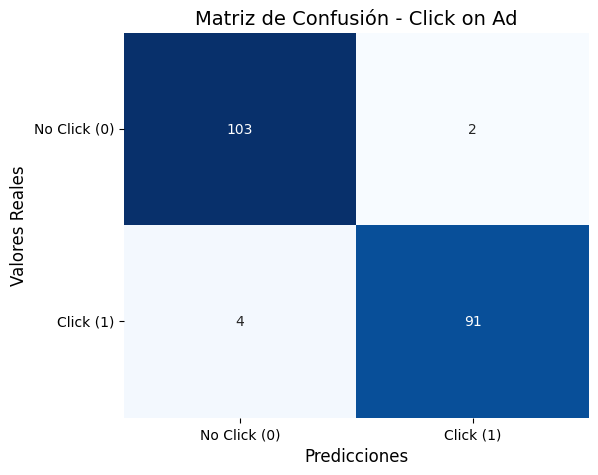

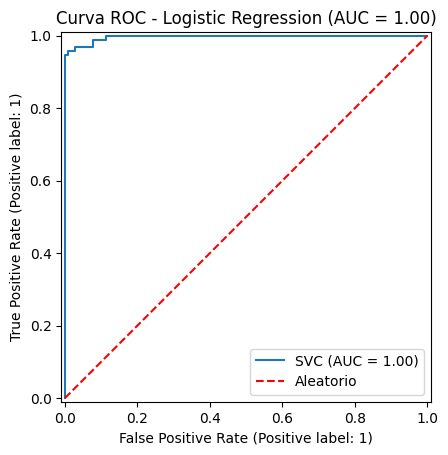

In [24]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns

# Matriz de confusión
con_matrix_2 = confusion_matrix(y_test, y_pred_2)

# Mostrar valores en consola
print("Matriz de Confusión:\n", con_matrix_2)

# Graficar matriz de confusión con seaborn
plt.figure(figsize=(6, 5))
sns.heatmap(con_matrix_2, annot=True, fmt="d", cmap="Blues", cbar=False)

plt.title("Matriz de Confusión - Click on Ad", fontsize=14)
plt.xlabel("Predicciones", fontsize=12)
plt.ylabel("Valores Reales", fontsize=12)
plt.xticks([0.5, 1.5], ["No Click (0)", "Click (1)"])
plt.yticks([0.5, 1.5], ["No Click (0)", "Click (1)"], rotation=0)
plt.show()

# === Curva ROC ===
from sklearn.metrics import roc_auc_score, RocCurveDisplay

y_proba = linear_model.predict_proba(X_test)[:, 1]  # Probabilidades clase positiva
auc_score = roc_auc_score(y_test, y_proba)

RocCurveDisplay.from_estimator(linear_model, X_test, y_test)
plt.plot([0, 1], [0, 1], "r--", label="Aleatorio")
plt.title(f"Curva ROC - Logistic Regression (AUC = {auc_score:.2f})")
plt.legend()
plt.show()


Una de las medidas  de SOTA más importantes esla obtención de la precision, recall y la dedida de desempeño f1-score. La medida de **presicion** se define como todos los valores que se predijeron como positivos y el **recall**  se define como todos los valores que realmente son positivos.
\begin{align}
precision=\frac{TP}{TP+FP} \quad
\end{align}
\begin{align}
recall=\frac{TP}{TP+FN} \quad
\end{align}
Sobre  la matriz de confusión podemos obtener la precision, recall y el f1-score.

La precision de la Clase=1.
\begin{align}
precision=\frac{91}{91+2}=0.978
\end{align}
El recall de la Clase=1
\begin{align}
recall=\frac{91}{91+4}=0.957
\end{align}
La precision de la Clase=0.
\begin{align}
precision=\frac{103}{103+4}=0.962
\end{align}
El recall de la Clase=0
\begin{align}
recall=\frac{103}{103+2}=0.98
\end{align}
La medida de desempeño de F1-score se define como la media armónica entre la precision y el recall:
\begin{align}
F1-score=2\cdot\frac{Precision \cdot Recall}{Precision+Recall}
\end{align}
El f1-score de la clase=1
\begin{align}
F1-score=2\cdot\frac{0.98 \cdot 0.96}{0.98+0.96} =0.97
\end{align}
El f1-score de la clase=0
\begin{align}
F1-score=2\cdot\frac{0.96 \cdot 0.98}{0.96+0.98} =0.97
\end{align}

In [25]:
from sklearn.metrics import classification_report
target_names = ['Clase 0','Clase 1']
print(classification_report(y_test, y_pred_2, labels=[0,1],target_names=target_names))

              precision    recall  f1-score   support

     Clase 0       0.96      0.98      0.97       105
     Clase 1       0.98      0.96      0.97        95

    accuracy                           0.97       200
   macro avg       0.97      0.97      0.97       200
weighted avg       0.97      0.97      0.97       200



# **CALCULO DEL ACCURACY**
Otra medida de desempeño importante es el accuracy que es mucho más global que el f1-score porque tiene en cuenta la información total de la matriz de confusión :
\begin{align}
accuracy=\frac{TP+TN}{TP+FP+FN+TN}
\end{align}
El accuracy para la matriz de confusión sería:
\begin{align}
accuracy=\frac{91+103}{91+2+4+103}=0,97
\end{align}